# NN_L1_default_rates

**Default rates of German credit applicants by checking-account status and of HMEQ home-equity loans by number of delinquent credit lines, against the sample average.**

Neural Networks and Deep Learning (NN), Lecture 1 · Daniel Traian Pele, Bucharest University of Economic Studies

[Open in Colab](https://colab.research.google.com/github/danpele/NEURAL_BIZ/blob/main/Quantlets/L1/NN_L1_default_rates/NN_L1_default_rates.ipynb)

In [1]:
import os
# course data: the local copy of the repository if there is one, else the public repository on GitHub
_LOCAL = os.path.join('..', '..', '..', 'data', 'clean')
DATA = _LOCAL + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/data/clean/'
REPO = os.path.join('..', '..', '..') + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/'

In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')
# course chart style: transparent background, no gridlines, legend at the bottom outside the axes, four-digit years
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#222222', 'axes.labelcolor': '#222222', 'xtick.color': '#222222', 'ytick.color': '#222222',
    'text.color': '#222222', 'font.size': 11, 'axes.labelsize': 11, 'legend.fontsize': 10.5, 'legend.frameon': False,
    'lines.linewidth': 1.4, 'font.family': 'DejaVu Sans'})
SERIES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
PAL = {'data': '#2a78d6', 'model': '#eb6834', 'benchmark': '#1baf7a', 'alt': '#eda100',
       'train': '#2a78d6', 'valid': '#eb6834', 'test': '#6250d6', 'positive': '#e34948', 'negative': '#2a78d6'}


def legend_bottom(fig, ncol=4):
    h, l_ = [], []
    for ax in fig.axes:
        for hh, ll in zip(*ax.get_legend_handles_labels()):
            if ll not in l_:
                h.append(hh); l_.append(ll)
    if h:
        fig.legend(h, l_, loc='lower center', ncol=min(ncol, len(h)), bbox_to_anchor=(0.5, 0.0), frameon=False)


def show(key, label, value):
    # print a number of the slide; [key] = its name in lectures/Lk/Lk_numbers.json
    print(f'{label} = {value}   [{key}]')

Lecture 1 of *Neural Networks and Deep Learning*: the chart `default_rates` of the slides, recomputed from the public data. Numbers printed with `show()` are the ones on the slide.

default rate, negative checking balance (%) = 49.3   [eda.chk.A11.pct]
default rate, no checking account (%) = 11.7   [eda.chk.A14.pct]
HMEQ default rate, no delinquent line (%) = 14.0   [eda.delinq.0.pct]
HMEQ default rate, 3+ delinquent lines (%) = 67.3   [eda.delinq.3plus.pct]


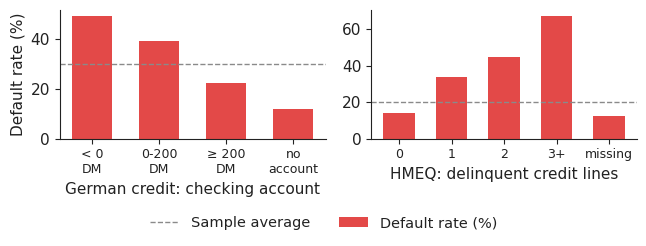

In [3]:
g = pd.read_csv(DATA + 'german_credit.csv'); hm = pd.read_csv(DATA + 'hmeq.csv')
chk = g.groupby('checking_status')['default'].mean()
d = hm['DELINQ']; cat = np.where(d.isna(), 'na', np.where(d >= 3, '3+', d.fillna(0).astype(int).astype(str)))
dq = hm.groupby(cat)['BAD'].mean()
show('eda.chk.A11.pct', 'default rate, negative checking balance (%)', round(100 * chk['A11'], 1))
show('eda.chk.A14.pct', 'default rate, no checking account (%)', round(100 * chk['A14'], 1))
show('eda.delinq.0.pct', 'HMEQ default rate, no delinquent line (%)', round(100 * dq['0'], 1))
show('eda.delinq.3plus.pct', 'HMEQ default rate, 3+ delinquent lines (%)', round(100 * dq['3+'], 1))
fig, axs = plt.subplots(1, 2, figsize=(6.6, 2.5))
ks = ['A11', 'A12', 'A13', 'A14']
axs[0].bar(range(4), 100 * chk[ks].values, color=PAL['positive'], width=0.6, label='Default rate (%)')
axs[0].set_xticks(range(4)); axs[0].set_xticklabels(['< 0\nDM', '0-200\nDM', '≥ 200\nDM', 'no\naccount'], fontsize=9)
axs[0].set_ylabel('Default rate (%)'); axs[0].set_xlabel('German credit: checking account')
order = ['0', '1', '2', '3+', 'na']
axs[1].bar(range(5), 100 * dq[order].values, color=PAL['positive'], width=0.6)
axs[1].set_xticks(range(5)); axs[1].set_xticklabels(['0', '1', '2', '3+', 'missing'], fontsize=9)
axs[1].set_xlabel('HMEQ: delinquent credit lines')
for ax, m in zip(axs, (g['default'].mean(), hm['BAD'].mean())):
    ax.axhline(100 * m, color='#8a8a8a', lw=1, ls='--', label='Sample average')
legend_bottom(fig); fig.tight_layout(rect=(0, 0.12, 1, 1))
fig.savefig('default_rates.png', dpi=200, transparent=True, bbox_inches='tight'); plt.show()